In [116]:
import pycbc.waveform
import pycbc.types as pcbcdt
import numpy as np

import time
import sys
import os

import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib import rc
# rc('text', usetex=True)

from astropy.cosmology import Planck18


from WF4Py import waveforms as WF
from WF4Py import WFutils as utils


# ourcodenameString = 'WF4Py'



In [117]:
def m1m2_from_Mceta(Mc, eta):
    # Define a function to compute the component masses of a binary given its chirp mass and symmetric mass ratio
    m1 = 0.5*(Mc/(eta**(3./5.)))*(1.+np.sqrt(1.-4.*eta))
    m2 = 0.5*(Mc/(eta**(3./5.)))*(1.-np.sqrt(1.-4.*eta))

    return m1, m2

In [118]:
zs = np.array([.2])

events = {'Mc':np.array([25])*(1.+zs), 'dL':(Planck18.luminosity_distance(zs).value/1000.),
         'iota':np.array([.0]),
        #  'eta':np.array([0.2]),
        # 'eta':np.array([0.16]), # 1/4
        'eta':np.array([8/81]), # 1/8
        #  'chi1z':np.array([0.02]), 'chi2z':np.array([-0.01]),
        #  'chi1z':np.array([0.2]), 'chi2z':np.array([-0.2]),
        #  'chi1z':np.array([0.8]), 'chi2z':np.array([-0.8]),
         'chi1z':np.array([0.98]), 'chi2z':np.array([-0.95]),
          'Lambda1':np.array([0.]), 'Lambda2':np.array([0.]), 'f_lower':np.array([20]), 'f_final':np.array([2048],), 'f_ref':np.array([30])}

In [119]:
# fig = plt.figure(figsize=(10,12))
# gs = gridspec.GridSpec(3,1,height_ratios=[2,1,.9])
# ax1 = plt.subplot(gs[0])
# ax2 = plt.subplot(gs[1], sharex=ax1)
# ax3 = plt.subplot(gs[2], sharex=ax1)
# ax1.plot(fgrids, PyCBCwfAmpl, 'C1', label=r'$\texttt{LAL}$', alpha=.35, linewidth=6.)
# ax1.plot(fgrids, myampl, 'C0', label=r'$\texttt{%s}$'%ourcodenameString)
# ax1.set_yscale('log')
# ax1.set_ylabel(r'$A_+ \, ({\rm Hz}^{-1})$',fontsize=20)
# ax1.grid()
# ax2.plot(fgrids, PyCBCwfPhase.real, 'C1', alpha=.35, linewidth=6.)
# ax2.plot(fgrids[:,0], np.cos(myphase[:,0]), 'C0',)
# ax2.set_ylabel(r'$\cos(\Psi_{+})$', fontsize=20)
# plt.xlabel(r'$f \, (\rm Hz)$', fontsize=20)
# yticks = ax2.yaxis.get_major_ticks()
# yticks[-1].label1.set_visible(False)
# ax3.plot(fgrids[:,0], abs(1.-(myampl[:,0])/(PyCBCwfAmpl)), '.', color='C2', ms=3)
# ax3.set_ylabel(r'$\rm res$', fontsize=20)
# ax1.set_xscale('log')
# ax3.set_yscale('log')

# plt.subplots_adjust(hspace=0.)

# handles, labels = ax1.get_legend_handles_labels()
# ax1.legend(handles[::-1], labels[::-1], loc='lower left', fontsize=20)

# ax1.tick_params(axis='both', which='major', labelsize=14)
# ax1.tick_params(axis='both', which='minor', labelsize=14)
# ax2.tick_params(axis='both', which='major', labelsize=14)
# ax2.tick_params(axis='both', which='minor', labelsize=14)
# ax3.tick_params(axis='both', which='major', labelsize=14)
# ax3.tick_params(axis='both', which='minor', labelsize=14)

# plt.xlim(min(fgrids), max(fgrids))
# ax1.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)
# ax2.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)
# ax3.grid(True, which='both', ls='dotted', linewidth='0.8', alpha=.8)

# ax1.set_title(r"{$\bf \texttt{IMRPhenomD}$}", fontsize=25)

# plt.show()

In [120]:
# tmpWF = WF.IMRPhenomD()

# fcut = tmpWF.fcut(**events)
# fminarr = np.full(fcut.shape, 5)
# fgrids = np.geomspace(fminarr, fcut, num=int(1000))

In [121]:
# myampl = tmpWF.Ampl(fgrids, **events)
# myphase = tmpWF.Phi(fgrids, **events)

In [122]:
m1s, m2s = m1m2_from_Mceta(events['Mc'], events['eta'])

# hp, hc = pycbc.waveform.get_fd_waveform_sequence(approximant='IMRPhenomD',
#                                                     mass1=m1s,
#                                                     mass2=m2s,
#                                                     spin1z=events['chi1z'],
#                                                     spin2z=events['chi2z'],
#                                                     sample_points = pcbcdt.array.Array(fgrids[:,0]),
#                                                     distance=events['dL']*1000.)

# PyCBCwfAmpl = np.array(abs(hp))
# PyCBCwfPhase = np.array(hp/abs(hp))

In [123]:
# plt.plot(np.cos((np.unwrap(np.angle(hp)) + myphase[:,0])[200:800]))

In [124]:
# Note that this model has various versions for both the phase and the amplitude
tmpWF = WF.IMRPhenomXAS(InsPhaseVersion=104.0, IntPhaseVersion=105, IntAmpVersion=104)

fcut = tmpWF.fcut(**events)
fminarr = np.full(fcut.shape, 5)
fgrids = np.geomspace(fminarr, fcut, num=int(1000))

myampl = tmpWF.Ampl(fgrids, **events)
myphase = tmpWF.Phi(fgrids, **events)
myphase0 = tmpWF.Phi0(fgrids, **events)

insphasever: 104.0
0


/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/WF4Py/waveform_models/IMRPhenomXAS.py:2502: RuntimeWarning: invalid value encountered in sqrt
  fAmpRDMin     = np.where(gamma2 <= 1., np.fabs(fring + fdamp * gamma3 * (np.sqrt(1. - gamma2 * gamma2) - 1.0) / gamma2), np.fabs(fring + fdamp*(-1.)*gamma3/gamma2))


In [125]:
m1m2_from_Mceta(events['Mc'], events['eta'])


(array([106.95614748]), array([13.36951843]))

In [126]:
events['chi2z'][0]

-0.95

insphasever: 104
0


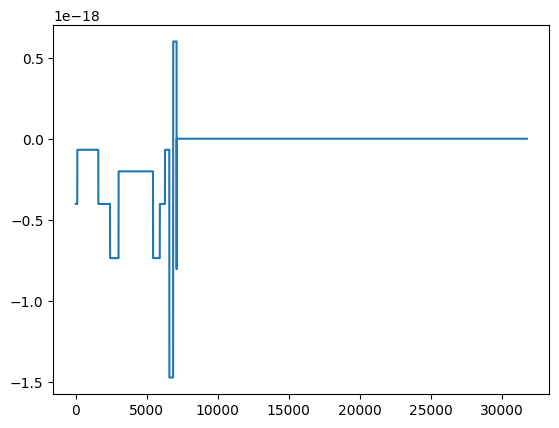

In [127]:
m1s, m2s = m1m2_from_Mceta(events['Mc'], events['eta'])

hp, hc = pycbc.waveform.get_fd_waveform_sequence(approximant='IMRPhenomXAS',
                                                    mass1=m1s,
                                                    mass2=m2s,
                                                    spin1z=events['chi1z'],
                                                    spin2z=events['chi2z'],
                                                    sample_points = pcbcdt.array.Array(fgrids[:,0]),
                                                    distance=events['dL']*1000.,
                                                    inclination=np.pi/3,
                                                    f_ref=events['f_ref'],
                                                    f_final=2048,
                                                    f_lower=20)
hpo, hco = pycbc.waveform.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=m1s[0],
                                                    mass2=m2s[0],
                                                    spin1z=events['chi1z'][0],
                                                    spin2z=events['chi2z'][0],
                                                    delta_f=1/16,
                                                    f_lower=20,
                                                    f_final=2048,
                                                    inclination=np.pi/3,
                                                    distance=events['dL'][0]*1000.,
                                                    f_ref=events['f_ref'][0])
hpd, hcd = pycbc.waveform.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=m1s[0],
                                                    mass2=m2s[0],
                                                    spin1z=events['chi1z'][0],
                                                    spin2z=events['chi2z'][0],
                                                    delta_f=1/16,
                                                    f_lower=20,
                                                    f_final=2048,
                                                    inclination=np.pi/3,
                                                    InsPhaseVersion=104,
                                                    # polarization=np.pi/2,
                                                    distance=events['dL'][0]*1000.,
                                                    f_ref=events['f_ref'][0])

hps, hcs = pycbc.waveform.get_fd_waveform_sequence(approximant='IMRPhenomXAS',
                                                    mass1=m1s,
                                                    mass2=m2s,
                                                    spin1z=events['chi1z'],
                                                    spin2z=events['chi2z'],
                                                    sample_points = hpd.sample_frequencies,
                                                    distance=events['dL']*1000.,
                                                    inclination=np.pi/3,
                                                    
                                                    f_ref=events['f_ref'],
                                                    f_final=2048,
                                                    f_lower=20)
# hpo, hco = pycbc.waveform.get_fd_waveform(approximant='IMRPhenomXAS',
#                                                     mass1=20,
#                                                     mass2=10,
#                                                     spin1z=0.01,
#                                                     spin2z=-0.01,
#                                                     delta_f=1/16,
#                                                     f_lower=20,
#                                                     f_final=2048,
#                                                     inclination=np.pi/3,
#                                                     coa_phase=0.3,
#                                                     distance=1000.,
#                                                     f_ref=20,
#                                                     InsPhaseVersion=104)
# hpd, hcd = pycbc.waveform.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
#                                                     mass1=20,
#                                                     mass2=10,
#                                                     spin1z=0.01,
#                                                     spin2z=-0.01,
#                                                     delta_f=1/16,
#                                                     f_lower=20,
#                                                     f_final=2048,
#                                                     coa_phase=0.3,
#                                                     inclination=np.pi/3,
#                                                     distance=1000.,
#                                                     f_ref=20,
#                                                     InsPhaseVersion=104)
# hp_gr_my0, hc_gr_my0 = pycbc.waveform.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
#                                                     mass1=30,
#                                                     mass2=30,
#                                                     spin1z=0,
#                                                     spin2z=0,
#                                                     delta_f=1/16,
#                                                     distance=1000,
#                                                     # mode_array = [[2,-2]],
#                                                     # inclination=events['inclination'],
#                                                     # coa_phase=events["coa_phase"],
#                                                     f_lower=20,
#                                                     f_ref=20,
#                                                     # InsPhaseVersion=isv,
#                                                     # choose_origin=False
#                                                     )

PyCBCwfAmpl = np.array(abs(hp))
PyCBCwfPhase = np.array(hp/abs(hp))

In [128]:
104==float(104.0)

True

In [129]:
# plt.plot(np.unwrap(np.angle(hp)))
# plt.plot(myphase)

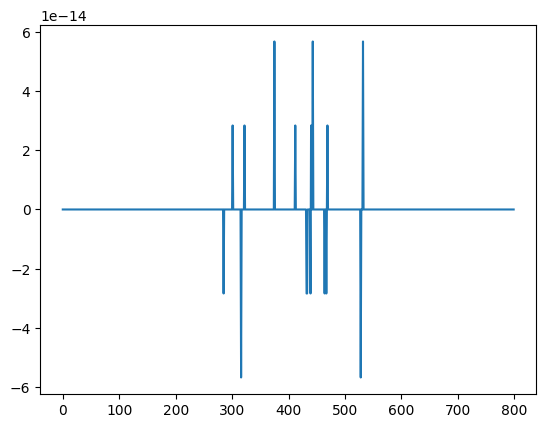

In [130]:
plt.plot(((myphase[:,0]-myphase0[:,0]))[0:800])
# plt.plot(())

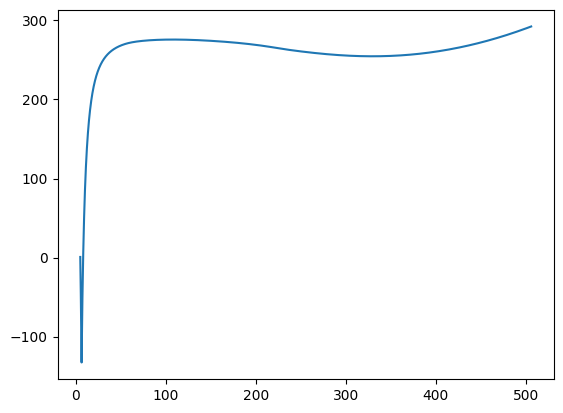

In [131]:
plt.plot(fgrids[:,0], (np.unwrap(np.angle(hp))))

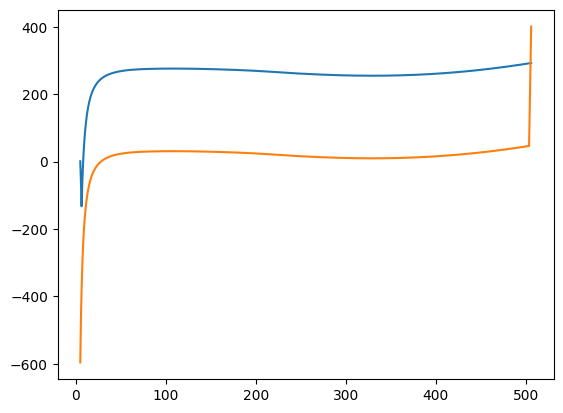

In [132]:
plt.plot(fgrids[:,0], (np.unwrap(np.angle(hp))))
plt.plot(fgrids[:,0], (myphase[:,0]))
# plt.plot(hpd.sample_frequencies, np.unwrap(np.angle(hpd)-np.angle(hpo)))
# plt.plot(hpo.sample_frequencies, np.unwrap(np.angle(hpo)))

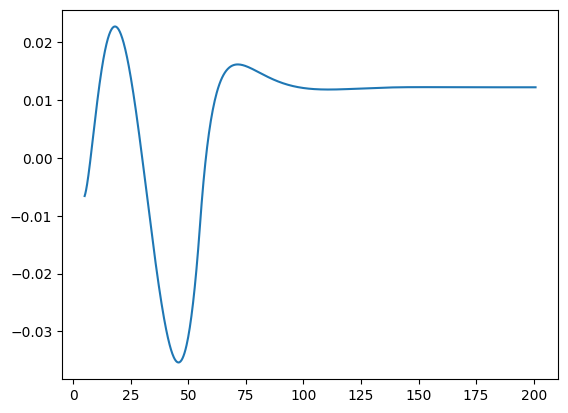

In [133]:
plt.plot(fgrids[:,0][0:800], np.sin(np.unwrap(np.angle(hp))-myphase[:,0])[0:800])

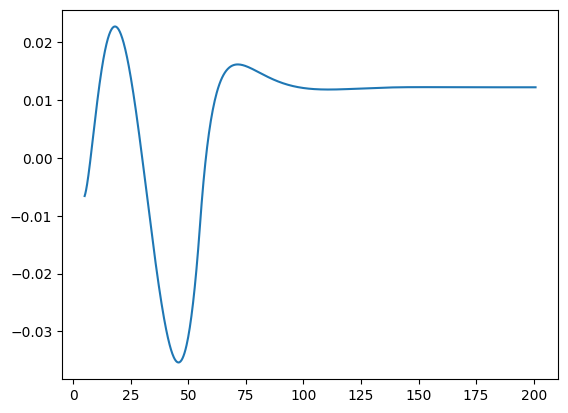

In [134]:
plt.plot(fgrids[:,0][0:800], np.sin(np.unwrap(np.angle(hp))-myphase[:,0])[0:800])


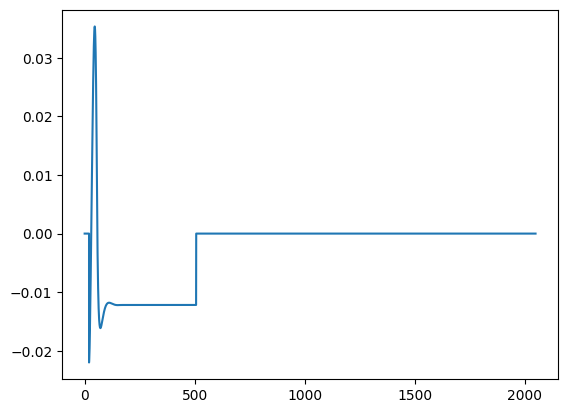

In [135]:
plt.plot(hpd.sample_frequencies, np.unwrap(np.angle(hpd.data))-np.unwrap(np.angle(hpo.data)));
# plt.plot(hcd.sample_frequencies, np.unwrap(np.angle(hcd.data))-np.unwrap(np.angle(hco.data)));

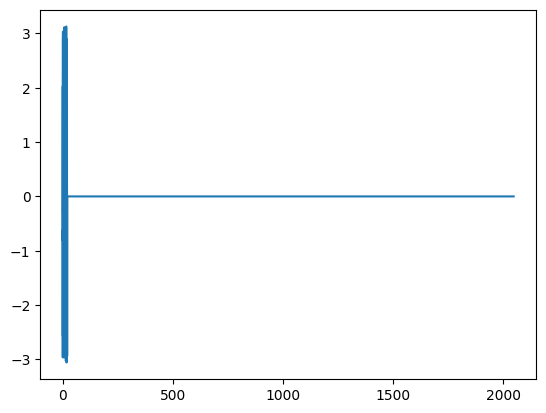

In [136]:
plt.plot(hpo.sample_frequencies, np.angle(hpo.data)-np.angle(hps.data));

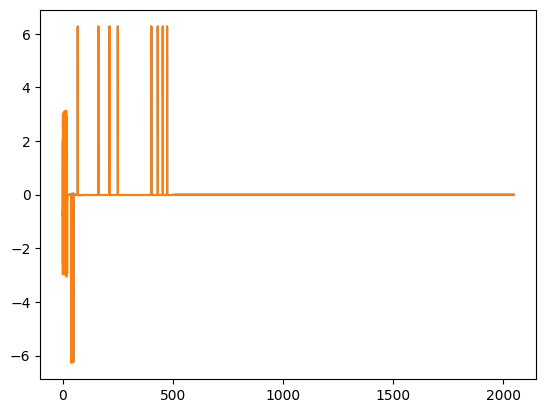

In [137]:
plt.plot(hpd.sample_frequencies, np.angle(hpd.data)-np.angle(hpo.data));
plt.plot(hpd.sample_frequencies, np.angle(hpd.data)-np.angle(hps.data));

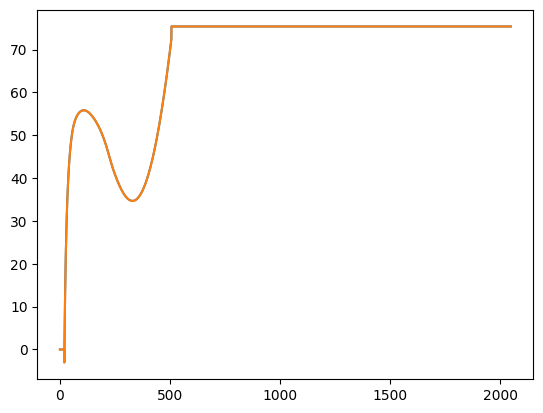

In [138]:
# plt.plot(fgrids[:,0], (myphase[:,0]))
plt.plot(hpo.sample_frequencies, np.unwrap(np.angle(hpo)))
plt.plot(hpd.sample_frequencies, np.unwrap(np.angle(hpd)))
# plt.ylim(0,20)

In [139]:
(np.unwrap(np.angle(hp)) - myphase[:,0])[10]

534.0644778043055

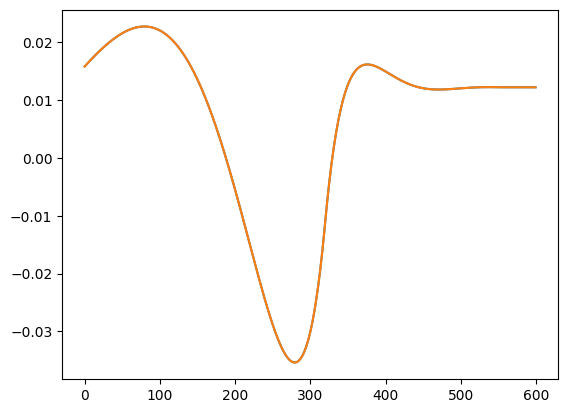

In [140]:
plt.plot(np.sin((np.unwrap(np.angle(hp)) - myphase[:,0])[200:800]))
plt.plot(np.sin((np.unwrap(np.angle(hp)) - myphase0[:,0])[200:800]))

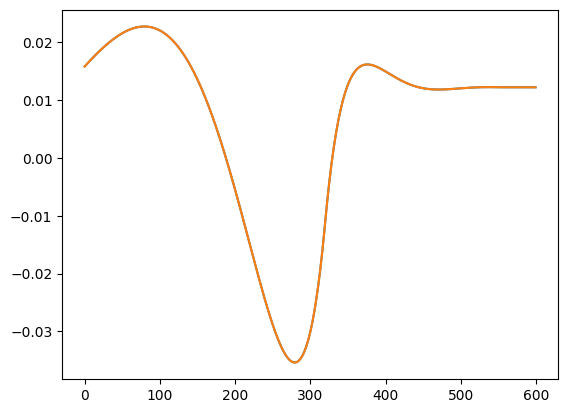

In [141]:
plt.plot(np.sin((np.unwrap(np.angle(hp)) - myphase[:,0])[200:800]))
plt.plot(np.sin((np.angle(hp) - myphase0[:,0])[200:800]))

In [142]:
np.sin((np.angle(hp) - myphase0[:,0])[200:800])**2+np.cos(np.angle(hp[200:800])-myphase[200:800, 0])**2;

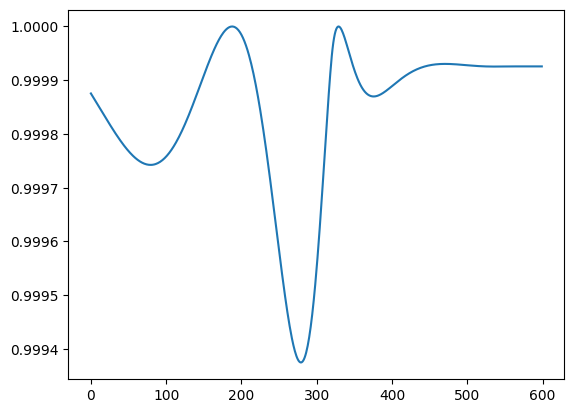

In [143]:
plt.plot(np.cos(np.angle(hp[200:800])-myphase[200:800, 0]))
# plt.plot()